# Controls: voltage comparison with $g_0 L^{0.25}$ at the best video-frame offset

Same rule as `EOD_accuracy_g0_L025_controls.ipynb` (my model, BEM conductivities, sink at the tail tip, sign fixed; the EOD goes to
the fish with the smallest $\lVert r - g_0 L_f^{0.25} m_f\rVert$, volts), but every fish's model is built from the masks of video
frame `Frame + offset` (`controls_offset_voltages.py`), at the offset where the emitter's model fits the recordings best:

- **3-fish**: the full sweep on all good-frame EODs (`EOD_offset_sweep_all_3fish.ipynb`, `offset_sweep_all_good.csv`, offsets −10…+10);
- **2-fish**: a sweep of the emitter on 300 random better-list EODs (offsets −10…+4), `offset_sweep_emitter_random300.csv`.

Best offset = smallest median shape distance d of the emitter (model × −1 and recording each scaled to max |v| = 1).
$g_0$ at that offset: median over the better list of the emitter's gain / $L_\mathrm{em}^{0.25}$ (in-sample); also shown with the
offset-0 $g_0$ of `EOD_baseline_g0.ipynb`. Compared with the earlier accuracies at offset 0 (same EODs, same sets).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

E, PX_PER_CM, N = 0.25, 912 / 60, 150
OUT = 'results/baseline_g0'
REC = {
    '3-fish (2024-10-15)': dict(res='results/eod_ground_truth_3fish', cache='conductivities/model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl',
                                sweep='conductivities/offset_sweep_all_good.csv', lengths='fish_lengths_3fish.json', fish=(0, 1, 2), emitter=0),
    '2-fish (2024-02-13)': dict(res='results/eod_ground_truth', cache='conductivities/model_voltages_N150_sinks0and0.05_el46ee63_bem_a453a8.pkl',
                                sweep='conductivities/offset_sweep_emitter_random300.csv', lengths='fish_lengths_2fish.json', fish=(0, 1), emitter=1),
}
G0_OFF0 = pd.read_csv(f'{OUT}/g0_controls.csv').set_index(['recording', 'EODs']).xs('all better-list EODs', level='EODs')['g0 = median g / L^e']

def wilson(k, n, z=1.96):
    p = k / n; c = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n); hw = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (c - hw), 100 * (c + hw)
unit = lambda x: x / np.abs(x).max(axis=-1, keepdims=True)

## Best offset

In [2]:
best, sweep_tab = {}, {}
for name, c in REC.items():
    s = pd.read_csv(f"{c['res']}/{c['sweep']}")
    med = s[[x for x in s.columns if x.startswith('d_') and x[2:].lstrip('-').isdigit()]].median()
    med.index = [int(x[2:]) for x in med.index]; med = med.sort_index()
    sweep_tab[name] = med; best[name] = int(med.idxmin())
display(pd.DataFrame(sweep_tab).round(3).rename_axis('offset (frames)'))
print('best offset:', best)

,3-fish (2024-10-15),2-fish (2024-02-13)
offset (frames),,
-10,0.655,0.407
-9,0.603,0.394
-8,0.546,0.362
-7,0.483,0.361
-6,0.422,0.354
-5,0.376,0.347
-4,0.364,0.355
-3,0.391,0.375
-2,0.441,0.387


best offset: {'3-fish (2024-10-15)': -4, '2-fish (2024-02-13)': -5}


## Accuracy

In [3]:
def pick(dist):
    dist = np.where(np.isfinite(dist), dist, np.inf)
    return np.where(np.isfinite(dist.min(1)), dist.argmin(1), -1)
def assign(R, M, scale): return pick(np.linalg.norm(R[:, None] - scale[None, :, None] * M, axis=2))

rows, g0_tab = [], {}
for name, c in REC.items():
    cache = pd.read_pickle(f"{c['res']}/{c['cache']}")
    A = pd.read_csv(f"{c['res']}/conductivities/eod_assignments.csv", index_col='row')
    assert (cache.frame.to_numpy() == A.Frame.to_numpy()).all()
    better = A.Frame.isin(pd.read_csv(f"{c['res']}/good_frames_better_list.csv").frame).to_numpy()
    sets = {'all EODs': np.ones(len(A), bool), 'better list of good frames': better}
    j = json.load(open(f"{c['res']}/{c['lengths']}"))
    L = np.array([j['fish'][str(f)]['L_px'] for f in c['fish']]) / PX_PER_CM
    R = np.stack(cache.v_rec.map(np.asarray))
    off = best[name]
    U = pd.read_pickle(f"{c['res']}/conductivities/model_voltages_N{N}_sink0_bem_offset{off}.pkl")
    M = -np.stack([U[int(k)] for k in A.Frame])                                   # (n, n_fish, n_pairs) at the best offset
    M0 = -np.stack(cache.u_sink0.map(lambda u: np.asarray(u, float)))              # offset 0
    em = c['emitter']
    ok = better & np.isfinite(M[:, em]).all(1)
    g = (R[ok] * M[ok, em]).sum(1) / (M[ok, em] ** 2).sum(1)
    g0_off = np.median(g) / L[em] ** E
    g0_tab[name] = {'best offset': off, 'g0 at best offset (in-sample)': g0_off, 'g0 at offset 0': G0_OFF0[name], 'n better-list EODs': ok.sum(),
                    '% EODs without all models at best offset': 100 * (~np.isfinite(M).all((1, 2))).mean()}
    picks = {
        'numerical, shape, best offset': pick(np.linalg.norm(unit(M) - unit(R)[:, None], axis=2)),
        'numerical, voltage, g0 L^0.25, best offset, g0 at best offset': assign(R, M, g0_off * L ** E),
        'numerical, voltage, g0 L^0.25, best offset, g0 at offset 0': assign(R, M, G0_OFF0[name] * L ** E),
        'numerical, voltage, g0 L^0.25, offset 0 (earlier)': assign(R, M0, G0_OFF0[name] * L ** E),
    }
    for s, m in sets.items():
        for p, f in picks.items():
            k, n = int((f[m] == em).sum()), int(m.sum()); lo, hi = wilson(k, n)
            rows.append({'recording': name, 'best offset': off, 'EODs': s, 'pipeline': p, '% correct': 100 * k / n, '95% CI low': lo, '95% CI high': hi, 'n EODs': n})
        old = pd.read_csv(f"{c['res']}/conductivities/accuracy_overall_4pipelines.csv")
        for _, o in old[(old.EODs == s) & old.pipeline.isin(['numerical, sink at tail tip', 'analytic, mask midline', 'analytic, SLEAP midline'])].iterrows():
            rows.append({'recording': name, 'EODs': s, 'pipeline': 'earlier: ' + o.pipeline.replace('numerical, sink at tail tip', 'numerical, shape, offset 0'),
                         '% correct': o['% correct'], '95% CI low': o['95% CI low'], '95% CI high': o['95% CI high'], 'n EODs': o['n EODs']})
display(pd.DataFrame(g0_tab).T.round(4))
ACC = pd.DataFrame(rows); ACC.to_csv(f'{OUT}/accuracy_g0_L025_offset_controls.csv', index=False)
display(ACC.pivot_table(index='pipeline', columns=['recording', 'EODs'], values='% correct', sort=False).round(2))

,best offset,g0 at best offset (in-sample),g0 at offset 0,n better-list EODs,% EODs without all models at best offset
3-fish (2024-10-15),-4.0,0.5222,0.4938,6751.0,0.3031
2-fish (2024-02-13),-5.0,0.2524,0.2474,3501.0,0.8950


recording                                          3-fish (2024-10-15)  \
EODs                                                          all EODs   
pipeline                                                                 
numerical, shape, best offset                                    90.37   
numerical, voltage, g0 L^0.25, best offset, g0 ...               91.35   
numerical, voltage, g0 L^0.25, best offset, g0 ...               91.22   
numerical, voltage, g0 L^0.25, offset 0 (earlier)                89.08   
earlier: numerical, shape, offset 0                              86.55   
earlier: analytic, SLEAP midline                                 82.44   
earlier: analytic, mask midline                                  86.99   

recording                                                                      \
EODs                                               better list of good frames   
pipeline                                                                        
numerical, shape, best offset                                           98.43   
numerical, voltage, g0 L^0.25, best offset, g0 ...                      98.84   
numerical, voltage, g0 L^0.25, best offset, g0 ...                      98.80   
numerical, voltage, g0 L^0.25, offset 0 (earlier)                       97.56   
earlier: numerical, shape, offset 0                                     94.50   
earlier: analytic, SLEAP midline                                        94.07   
earlier: analytic, mask midline                                         95.20   

recording                                          2-fish (2024-02-13)  \
EODs                                                          all EODs   
pipeline                                                                 
numerical, shape, best offset                                    96.92   
numerical, voltage, g0 L^0.25, best offset, g0 ...               96.97   
numerical, voltage, g0 L^0.25, best offset, g0 ...               97.08   
numerical, voltage, g0 L^0.25, offset 0 (earlier)                92.50   
earlier: numerical, shape, offset 0                              93.65   
earlier: analytic, SLEAP midline                                 89.75   
earlier: analytic, mask midline                                  93.09   

recording                                                                      
EODs                                               better list of good frames  
pipeline                                                                       
numerical, shape, best offset                                           99.09  
numerical, voltage, g0 L^0.25, best offset, g0 ...                      99.34  
numerical, voltage, g0 L^0.25, best offset, g0 ...                      99.46  
numerical, voltage, g0 L^0.25, offset 0 (earlier)                       97.14  
earlier: numerical, shape, offset 0                                     96.74  
earlier: analytic, SLEAP midline                                        95.94  
earlier: analytic, mask midline                                         96.97

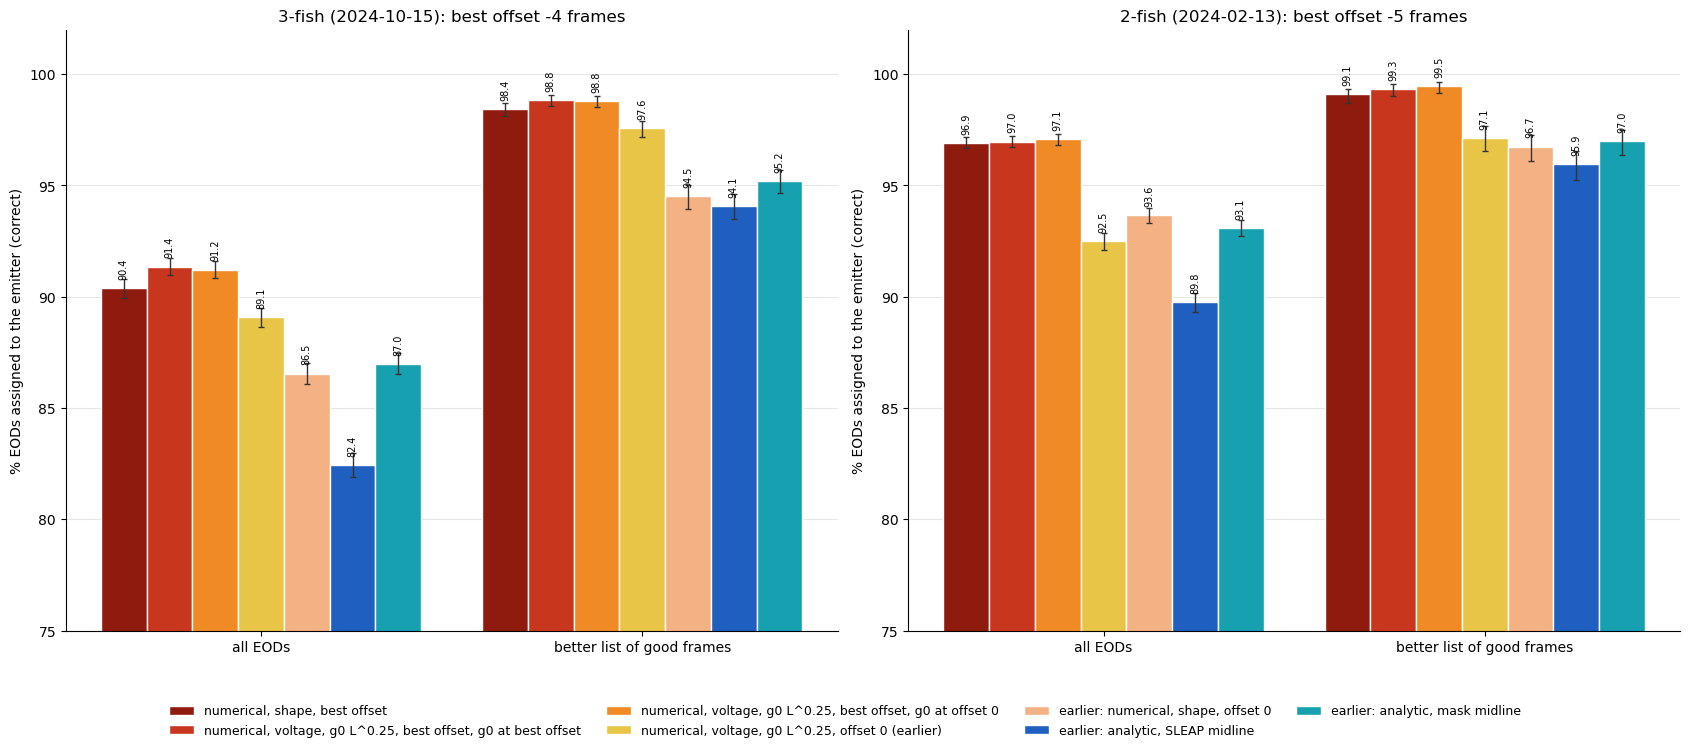

In [4]:
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3'})
fig, axs = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, name in zip(axs, REC):
    t = ACC[ACC.recording == name]
    pipes = list(dict.fromkeys(t.pipeline))
    warm = ['#8E1B0E', '#C8361E', '#F08A24', '#E8C547', '#F4B183']; cold = ['#1F5FBF', '#17A0B0']
    col = {p: (cold.pop(0) if 'analytic' in p else warm.pop(0)) for p in pipes}
    for j, p in enumerate(pipes):
        q = t[t.pipeline == p].set_index('EODs').loc[['all EODs', 'better list of good frames']]
        xs = np.arange(2) + (j - (len(pipes) - 1) / 2) * 0.12
        ax.bar(xs, q['% correct'], 0.12, color=col[p], edgecolor='white', label=p)
        ax.errorbar(xs, q['% correct'], yerr=[q['% correct'] - q['95% CI low'], q['95% CI high'] - q['% correct']], fmt='none', ecolor='0.2', capsize=2, lw=1)
        for xx, v in zip(xs, q['% correct']): ax.text(xx, v + 0.4, f'{v:.1f}', ha='center', va='bottom', fontsize=7, rotation=90)
    ax.set(xticks=[0, 1], xticklabels=['all EODs', 'better list of good frames'], ylim=(75, 102), ylabel='% EODs assigned to the emitter (correct)',
           title=f'{name}: best offset {best[name]} frames')
    ax.set_axisbelow(True); ax.grid(axis='x', visible=False)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, ncol=4, fontsize=9, loc='lower center', frameon=False)
plt.tight_layout(rect=(0, 0.1, 1, 1)); fig.savefig(f'{OUT}/accuracy_g0_L025_offset_controls.png', dpi=120); plt.show()